# Step 2 — Skew correction (projection profile, binary only)

`src/skew_correction.py`: angle θ* = argmax S(θ) = Σ_k p_θ(k)² over [−90°, 90°) (coarse 1°, fine 0.1° within ±1°, wrapped mod 180°), estimated on the **binary** image from Step 1 (`run_adaptive` = adaptive Otsu, called once). The **same binary** is rotated: `np.rot90` for the 90° part + nearest-neighbour inverse mapping (NumPy, enlarged canvas, outside = paper) for the remainder, so it stays 0/255 — no grayscale, no interpolation, no re-binarization. Fallback θ = 0 when r = S(θ*)/median S < `R_MIN`.
No border / large-blob filter yet (all ink pixels count). Spec: `Claude Chat Memory/Skew_Correction.md`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt

import src.adaptive_thresholding as at
import src.skew_correction as sk
print(f"BLOCK={at.BLOCK}, C={at.C}, R_MIN={sk.R_MIN}")

BLOCK=33, C=9, R_MIN=2.8


In [2]:
photo_dir = ROOT / "data" / "raw" / "photos"
photos = [p for p in sorted(photo_dir.glob("*")) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
binaries = {f"photo {i + 1}": at.run_adaptive(p) for i, p in enumerate(photos)}   # Step 1, once
{k: p.name for k, p in zip(binaries, photos)}

{'photo 1': 'PHOTO-2026-11-20-23-54-12.jpg',
 'photo 2': 'PHOTO-2026-11-21-01-41-35.jpg',
 'photo 3': 'PHOTO-2026-11-21-22-38-16.jpg',
 'photo 4': 'test.png'}

## 1. Per photo: Step-1 binary | S(θ) | rotated binary

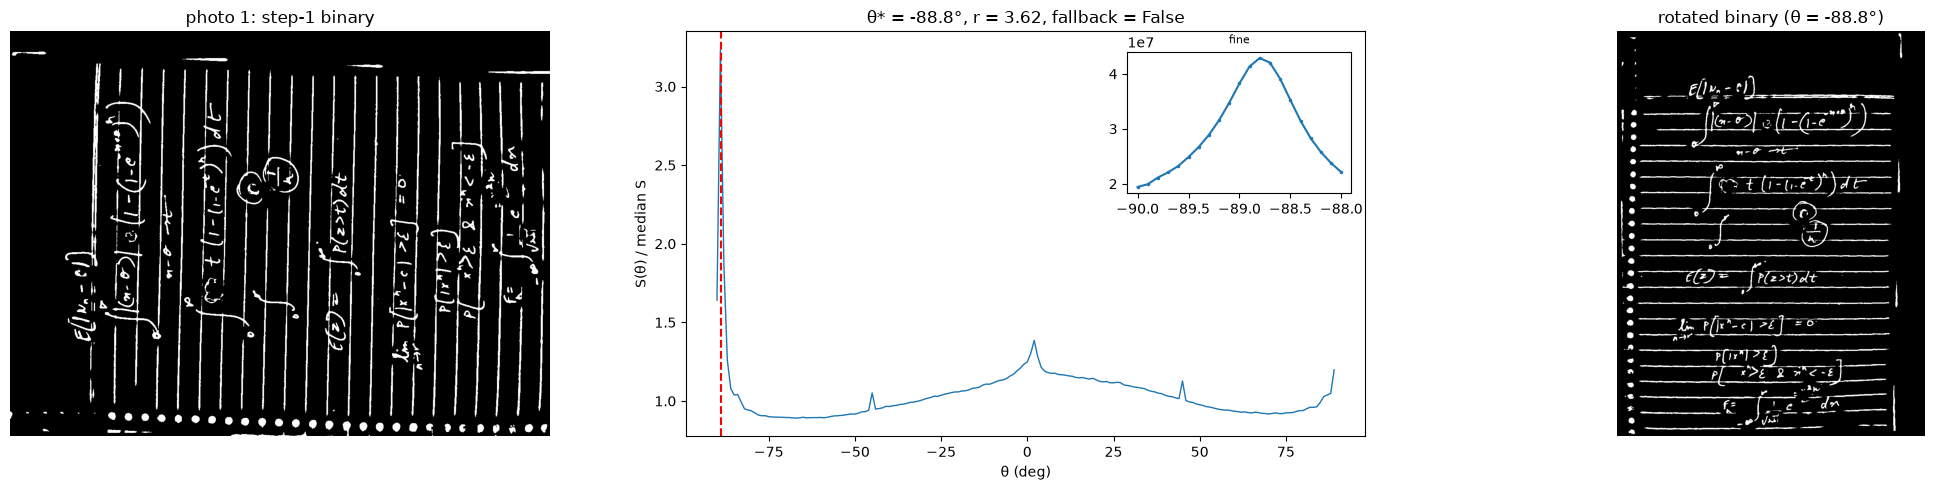

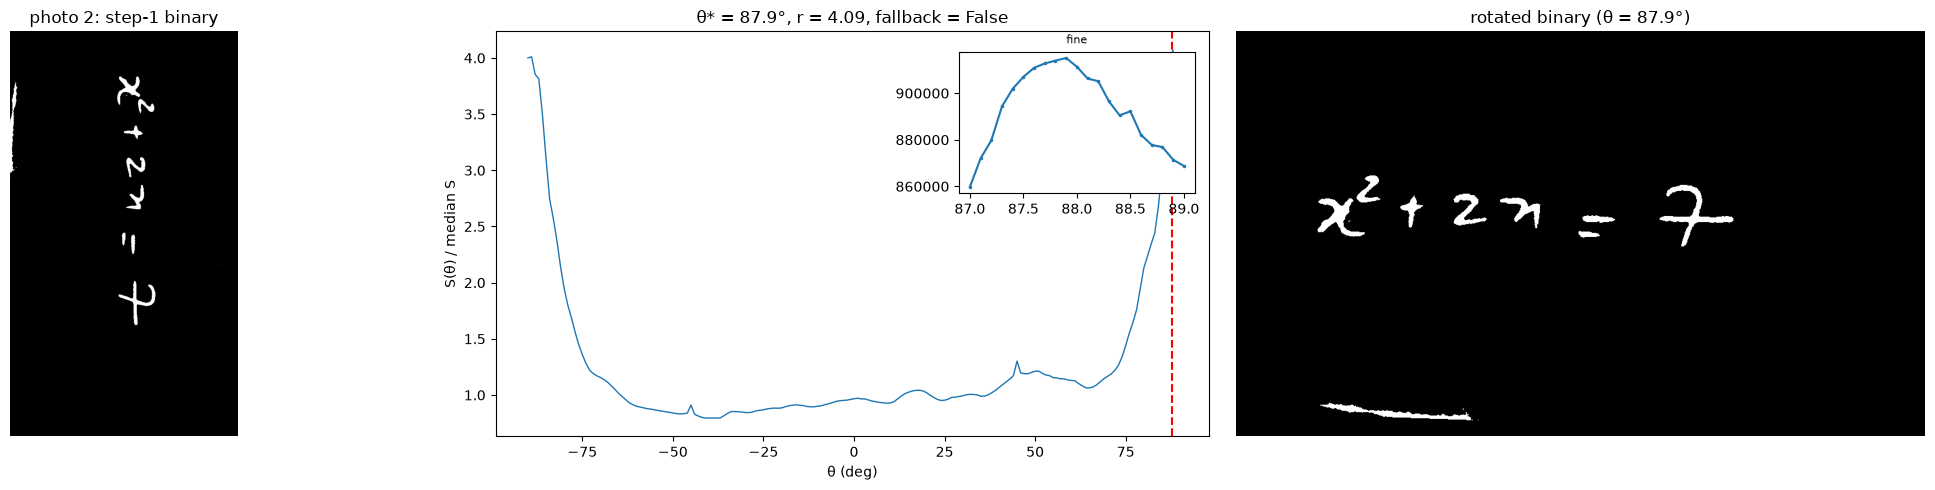

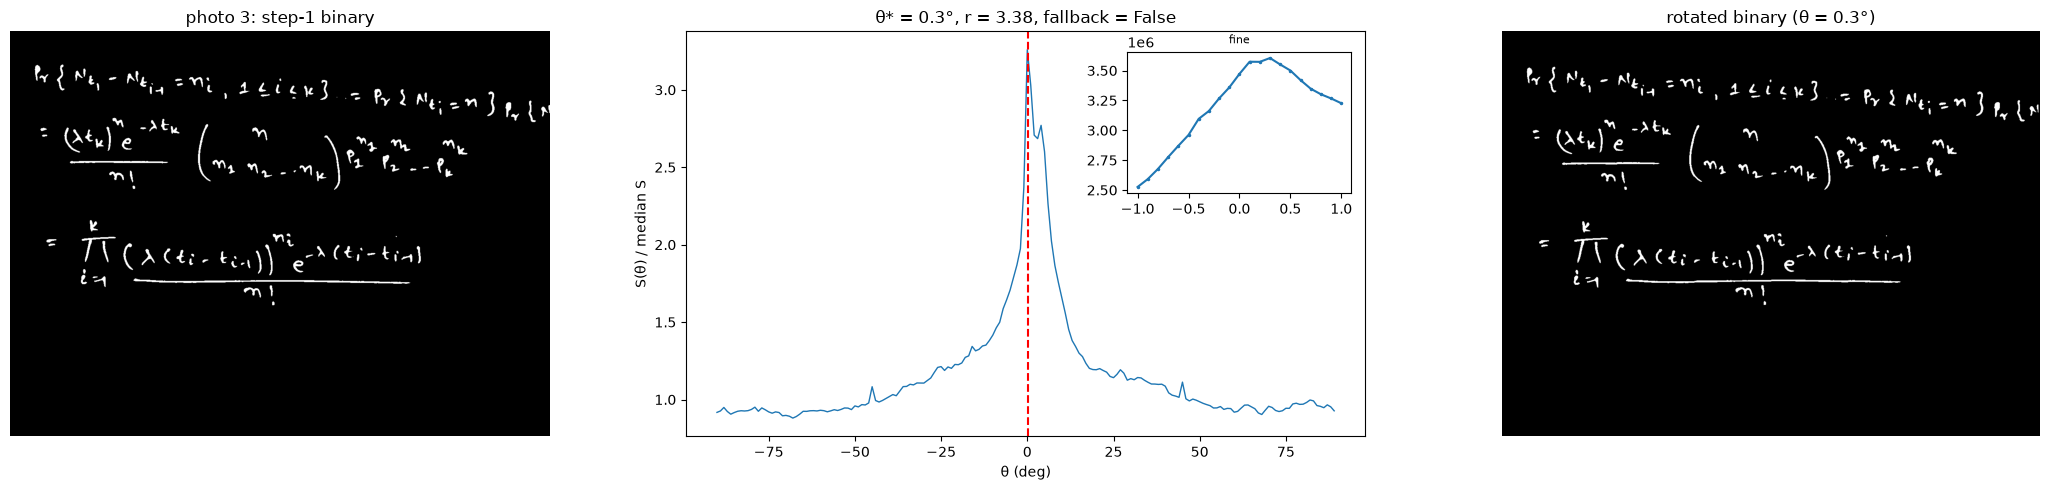

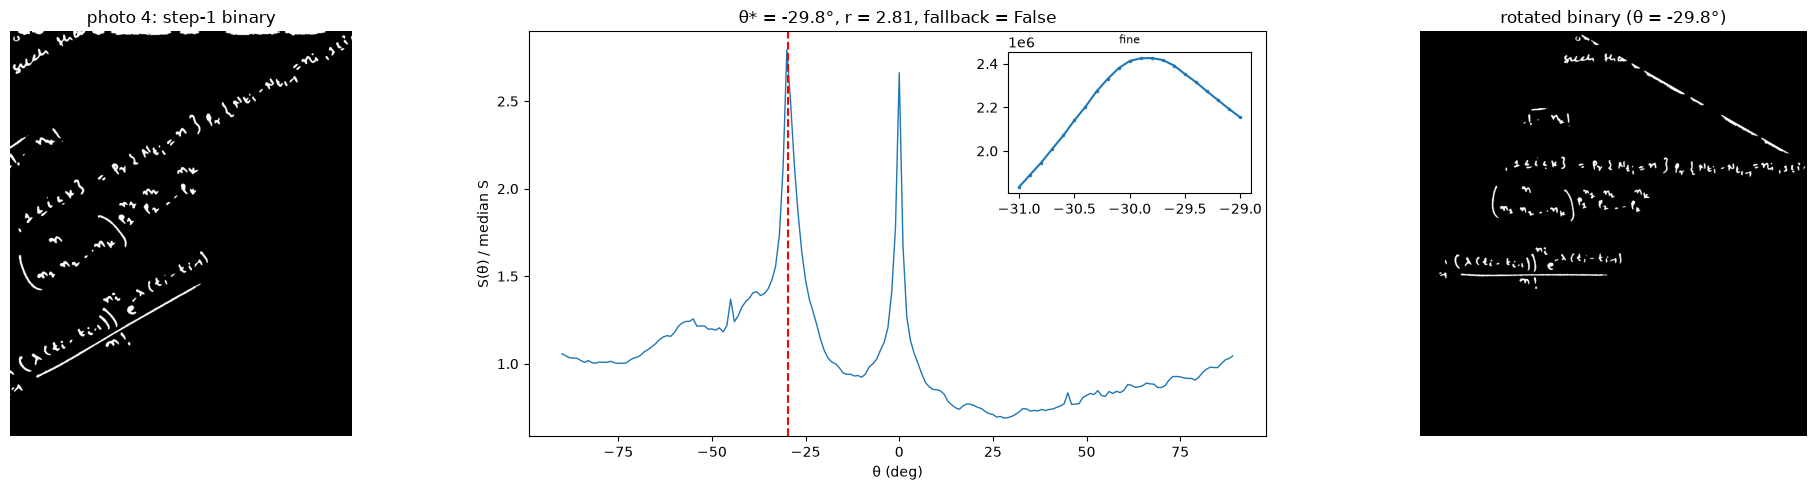

In [3]:
infos = {}
for name, binary in binaries.items():
    rot, info = sk.deskew(binary)
    infos[name] = info
    fig, ax = plt.subplots(1, 3, figsize=(22, 5))
    ax[0].imshow(binary, cmap="gray"); ax[0].set_title(f"{name}: step-1 binary")
    ax[1].plot(info["angles"], info["scores"] / np.median(info["scores"]), lw=1)
    ax[1].axvline(info["theta_raw"], color="r", ls="--")
    ax[1].set_xlabel("θ (deg)"); ax[1].set_ylabel("S(θ) / median S")
    ax[1].set_title(f"θ* = {info['theta_raw']:.1f}°, r = {info['r']:.2f}, fallback = {info['fallback']}")
    ins = ax[1].inset_axes([0.65, 0.6, 0.33, 0.35])
    ins.plot(info["fine_angles"], info["fine_scores"], ".-", ms=3); ins.set_title("fine", fontsize=8)
    ax[2].imshow(rot, cmap="gray"); ax[2].set_title(f"rotated binary (θ = {info['theta']:.1f}°)")
    for a in ax[[0, 2]]: a.axis("off")
    plt.tight_layout(); plt.show()

### Stair-stepping check
Nearest-neighbour rotation makes stroke edges slightly stair-stepped (spec: accepted trade-off). Zoom on a stroke of photo 4 (largest rotation) before / after; ink-pixel count should be ~unchanged.

ink pixels: before 22793, after 22763, values after: [  0 255]


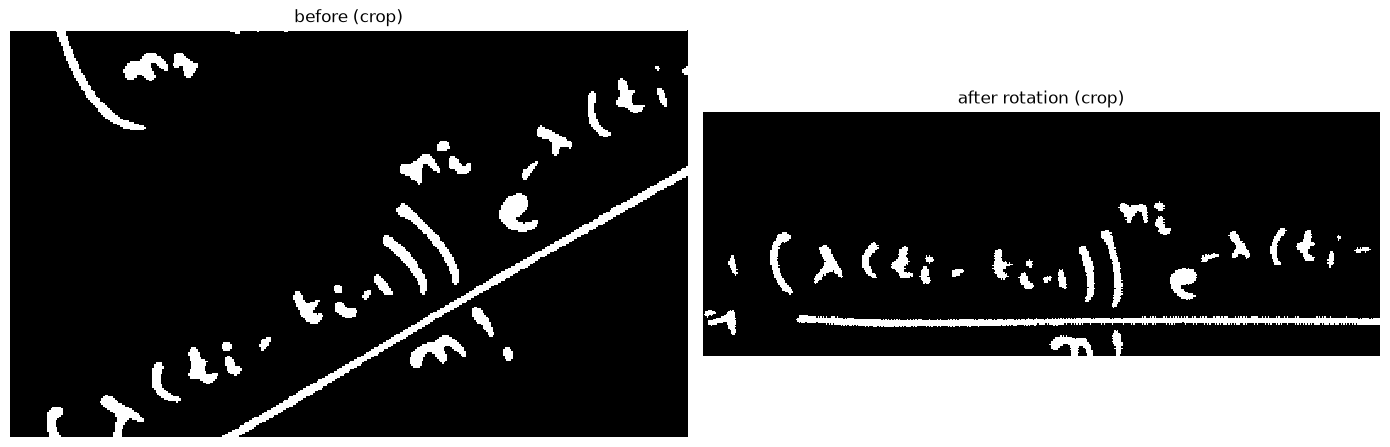

In [4]:
b4 = binaries["photo 4"]
r4 = sk.rotate_binary(b4, infos["photo 4"]["theta"])
print(f"ink pixels: before {int((b4 > 0).sum())}, after {int((r4 > 0).sum())}, values after: {np.unique(r4)}")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(b4[580:820, 0:400], cmap="gray", interpolation="nearest"); ax[0].set_title("before (crop)")
ax[1].imshow(r4[620:800, 60:560], cmap="gray", interpolation="nearest"); ax[1].set_title("after rotation (crop)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 2. Angle-error test

Rotate an upright **binary** by known angles θ_true (−15…15° in 2.5° steps, plus 60°, ±90°) with `rotate_binary`, estimate. Expected estimate = θ_ref − θ_true (θ_ref = estimate on the unrotated reference); error taken mod 180°.
References: (a) **synthetic level text** (unambiguous 0°), (b) **photo 3 deskewed** (lines not all parallel, see observations).

== synthetic level text  (θ_ref = 0.0°)
 θ_true   θ̂     |error|   r
 -15.0    15.0    0.00    3.11
 -12.5    12.5    0.00    3.11
 -10.0    10.0    0.00    3.12
  -7.5     7.5    0.00    3.11
  -5.0     5.0    0.00    3.11
  -2.5     2.5    0.00    3.11
   0.0     0.0    0.00    3.12
   2.5    -2.5    0.00    3.11
   5.0    -5.0    0.00    3.11
   7.5    -7.5    0.00    3.11
  10.0   -10.0    0.00    3.11
  12.5   -12.5    0.00    3.11
  15.0   -15.0    0.00    3.11
  60.0   -60.0    0.00    3.12
  90.0   -90.0    0.00    3.12
 -90.0   -90.0    0.00    3.12


== photo 3 deskewed  (θ_ref = -0.1°)
 θ_true   θ̂     |error|   r
 -15.0    14.9    0.00    3.33
 -12.5    12.4    0.00    3.34
 -10.0     9.9    0.00    3.34
  -7.5     7.4    0.00    3.33
  -5.0     4.9    0.00    3.34
  -2.5     2.4    0.00    3.32
   0.0    -0.1    0.00    3.36
   2.5    -2.6    0.00    3.31
   5.0    -5.1    0.00    3.32
   7.5    -7.6    0.00    3.33
  10.0   -10.1    0.00    3.34
  12.5   -12.6    0.00    3.34
  15.0   -15.1    0.00    3.34
  60.0   -60.1    0.00    3.34
  90.0   -90.0    0.10    3.37
 -90.0    89.9    0.00    3.36


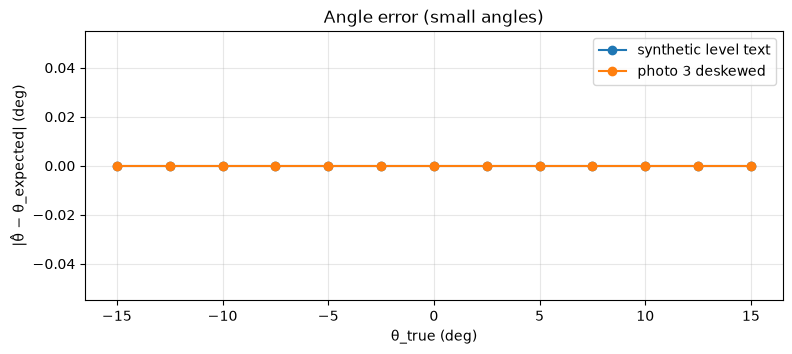

In [5]:
def synthetic_page(h=600, w=1000):
    img = np.full((h, w), 215, np.uint8)
    for i, s in enumerate(["x^2 + 2x = 7", "a(b + c) = ab + ac", "y = 3x - 1", "(x + 1)(x - 1) = x^2 - 1"]):
        cv2.putText(img, s, (60, 110 + 130 * i), cv2.FONT_HERSHEY_SIMPLEX, 1.8, 50, 4)
    noisy = np.clip(img + np.random.default_rng(0).normal(0, 4, img.shape), 0, 255).astype(np.uint8)
    return at.adaptive_otsu(at.gaussian_blur(noisy))[0]

references = {"synthetic level text": synthetic_page(), "photo 3 deskewed": sk.deskew(binaries["photo 3"])[0]}
true_angles = list(np.arange(-15, 15.1, 2.5)) + [60, 90, -90]

errors = {}
for ref_name, ref in references.items():
    theta_ref = sk.estimate_skew(ref)["theta_raw"]
    rows = []
    for a in true_angles:
        est = sk.estimate_skew(sk.rotate_binary(ref, a))
        rows.append((a, est["theta_raw"], abs(sk.wrap_angle(est["theta_raw"] - (theta_ref - a))), est["r"]))
    errors[ref_name] = rows
    print(f"== {ref_name}  (θ_ref = {theta_ref:.1f}°)")
    print(" θ_true   θ̂     |error|   r")
    for a, e, err, r in rows:
        print(f"{a:6.1f} {e:7.1f} {err:7.2f} {r:7.2f}")

plt.figure(figsize=(9, 3.5))
for ref_name, rows in errors.items():
    plt.plot([r[0] for r in rows[:-3]], [r[2] for r in rows[:-3]], "o-", label=ref_name)
plt.xlabel("θ_true (deg)"); plt.ylabel("|θ̂ − θ_expected| (deg)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Angle error (small angles)"); plt.show()

## 3. Choosing `R_MIN` by eye

r on the full photos and on crops of photo 3 (single lines, single symbols): where is the estimated angle meaningful (text visibly levelled) and where is it noise?

photo 1              θ* =  -88.8   r = 3.62
photo 2              θ* =   87.9   r = 4.09


photo 3              θ* =    0.3   r = 3.38
photo 4              θ* =  -29.8   r = 2.81
photo 3, line 1      θ* =    4.3   r = 9.43
photo 3, line 3      θ* =    0.1   r = 9.20
single Π             θ* =  -79.0   r = 2.62
single =             θ* =   -9.4   r = 1.79
single e             θ* =  -45.0   r = 1.27


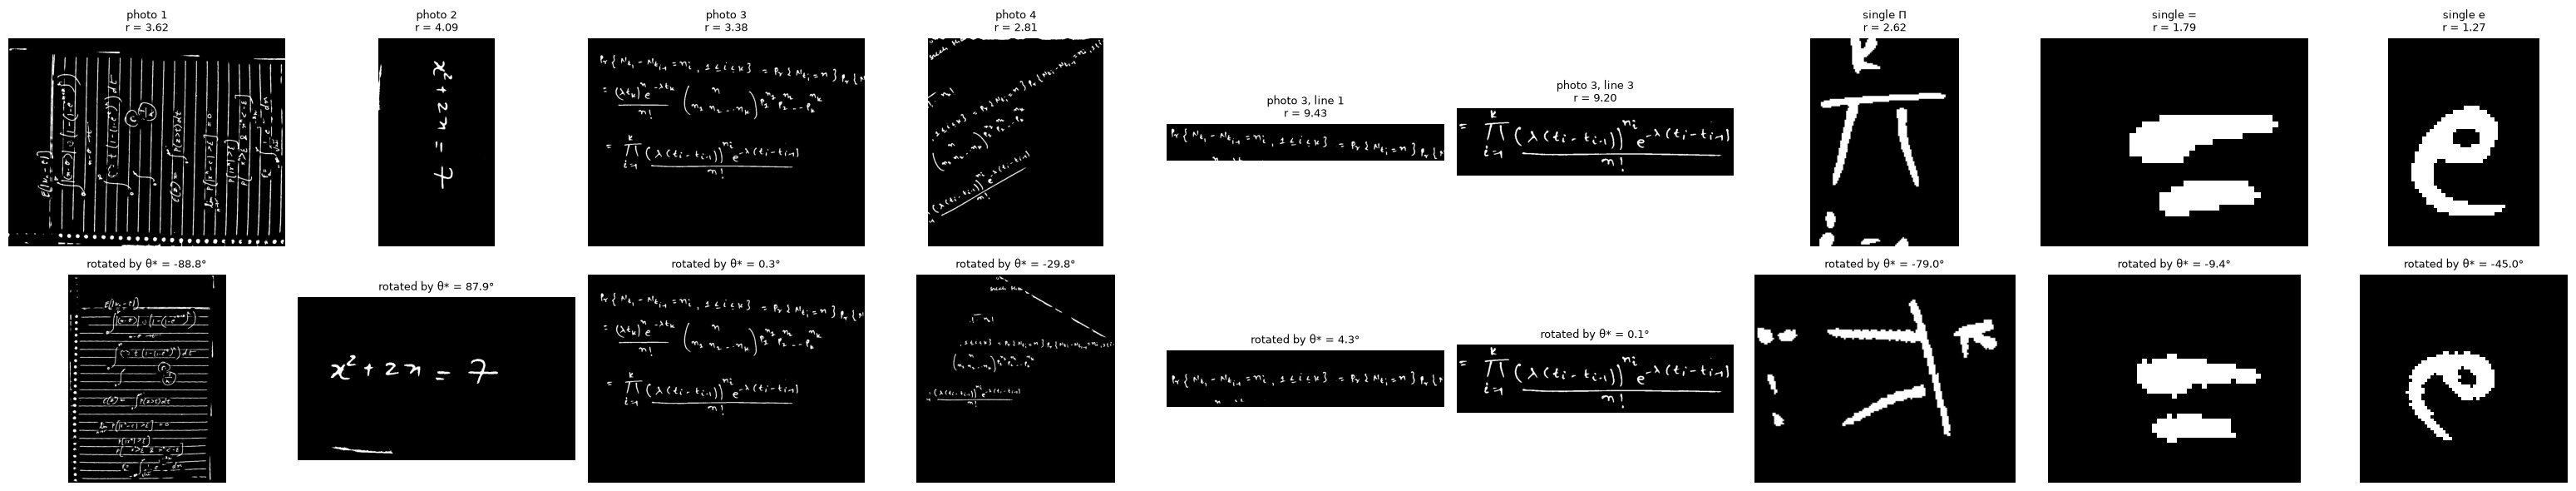

In [6]:
b3 = binaries["photo 3"]
crops = {"photo 3, line 1": b3[60:230, 40:1330], "photo 3, line 3": b3[460:690, 80:1030],
         "single Π": b3[470:610, 170:270], "single =": b3[500:535, 75:120], "single e": b3[245:300, 270:310]}
cases = binaries | crops

fig, ax = plt.subplots(2, len(cases), figsize=(3.5 * len(cases), 6))
for j, (name, bin_) in enumerate(cases.items()):
    info = sk.estimate_skew(bin_, r_min=0)          # no fallback: see what rotation would do
    ax[0, j].imshow(bin_, cmap="gray"); ax[0, j].set_title(f"{name}\nr = {info['r']:.2f}", fontsize=9)
    ax[1, j].imshow(sk.rotate_binary(bin_, info["theta_raw"]), cmap="gray")
    ax[1, j].set_title(f"rotated by θ* = {info['theta_raw']:.1f}°", fontsize=9)
    print(f"{name:20s} θ* = {info['theta_raw']:6.1f}   r = {info['r']:.2f}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

**Chosen `R_MIN = 2.8`.** Single symbols give r ≈ 1.2–2.6 with meaningless angles (Π → −79°, `e` → −45°); every real text region (full photos, single lines) gives r ≥ ~2.8 and a sensible angle. 2.8 sits in the gap, but the margin is small (Π 2.62 vs `test.png` 2.81 with the adaptive-Otsu binary) and rests on 4 photos. The spec's starting value 1.05 never triggers: r is a ratio to the *median* over 180 angles, which is low for any non-trivial ink.

## 4. Observations

First analysis, on an **earlier Step-1 version** (before the final adaptive-mean parameters):

| Photo | θ* | r | Result |
|---|---|---|---|
| 1 (lined page, sideways) | 2.2° | 3.05 | **wrong**: horizontal page edge, row of spiral holes and timestamp outweigh the vertical text / ruled lines (second peak at −89°). A centre crop gives −88.8° → the deferred border/large-blob filter is what is missing. |
| 2 (`x²+2x=7`, sideways) | −85.4° | 4.11 | levelled but **upside-down**: S(θ) = S(θ+180°) (expected; classifier confidence after Step 6). No fallback: r is high even for one short expression. |
| 3 (upright, multi-line) | 0.1° | 3.11 | kept upright; line 1 alone is tilted ~4°, the rest ~0°: one global angle can't fix both. |
| 4 (multi-line, tilted ~30°) | −30.0° | 3.05 | **levelled correctly**. |

Final adaptive-mean Step 1 vs adaptive-Otsu Step 1 (current: blank tiles = paper, no global cutoff):

| Photo | adaptive mean θ* / r | adaptive Otsu θ* / r | Result with adaptive Otsu |
|---|---|---|---|
| 1 | −88.8° / 2.89 | −88.8° / 3.62 | levelled (higher r) |
| 2 | −85.8° / 3.90 | 87.9° / 4.09 | levelled and now **upright** (the 180° choice is still luck: S(θ) = S(θ+180°)) |
| 3 | 0.1° / 3.25 | 0.3° / 3.38 | kept upright |
| 4 (`test.png`) | −29.8° / 2.97 | −29.8° / 2.81 | levelled, but r only just above `R_MIN` |

An intermediate adaptive-Otsu version (blank tiles = window mean − C) failed on photos 1 and 4 (page-edge bar dominated S(θ)); making blank tiles all paper fixed both.

- Angle-error test: synthetic level text 0.0° error everywhere; photo 3 ≤ 0.1° (incl. 60°, ±90°). With the earlier grayscale + `BORDER_REPLICATE` rotation photo 3 had ~3° errors at some angles (smeared border streaks); rotating the binary with outside = paper removed them.
- Nearest-neighbour rotation keeps 0/255 and the ink count; edges are slightly stair-stepped (see zoom) — acceptable per spec.
- Needed later: border/large-blob filter (page edges still count in S(θ); photo 4 is close to the fallback), 180° decision (photo 2); per-line tilt / perspective (photo 3) out of scope.